# 最低賃金の発効時期とパート求人：二期の採用選択
課題3（モデル・仮説）と課題4（実データ検証）。既発表の2025年11月・早20県対晩14県を主比較として残す。

このnotebookはリポジトリ内で実行済み。未公開のColabリンクは使わない。`analysis.py`を唯一の計算本体とし、rawファイルは読むだけである。結果の単位は対数差×100で、求人数はハローワーク新受理の採用予定人数、実際の採用・雇用ではない。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
H=Path.cwd()
assert (H/"analysis.py").is_file(), "notebookのある03-dynamicから実行してください"
sys.path.insert(0,str(H))
import analysis as a
summary=a.run_all()
print("実行完了：rawの書換えなし")

実行完了：rawの書換えなし


## 1. 読み込みと検査
年・年度平均行を除き、月次の164か月を検査。47県、全国合計、一般パート＋一般パートを除く一般＝一般計、前年同月との対応、年度見出しを確認する。分析部分は2023年1月〜2026年8月の2,068県月。2024年の賃金・発効日は別の厚労省PDF全47県と照合する。

In [2]:
display(pd.Series(summary["data"]["checks"],name="passed"))
print(summary["data"]["policy_columns"])
print(summary["data"]["raw_sha256"])

47_prefectures                    True
monthly_continuity                True
unique_months                     True
positive_no_missing               True
national_equals_pref_sum          True
part_plus_nonpart_equals_total    True
same_months_all_sheets            True
policy_exact_pref_join            True
policy_2025_year                  True
group_counts                      True
analysis_47_by_44_no_missing      True
official_2024_pdf_47_matches      True
Name: passed, dtype: bool

{'2023': {'label': '令和５年度', 'zero_based_column': 43}, '2024': {'label': '令和６年度', 'zero_based_column': 45}, '2025': {'label': '令和７年度', 'zero_based_column': 47}}
{'estat_shokugyo_t12_shinki_kyujin.xlsx': '8b7e5d360b2c6b887f819c35efef2d4096ce7d077e38e8c73ef2c56eed1438c5', 'mhlw_saitei_chingin_kaitei.xlsx': '5745e93632b6221aa44712d9bab1ff2d790d713ae5e1d5cca62c77c76d3d1986'}


## 2. 比較できる暦月
11月は早群20県が全月適用、晩群14県は全月未発効。ただし企業が未来の賃金を予想する場合、法的未発効は経済的な未処置を意味しない。8月4日に目安公表、9月5日に全県の答申が集約された。7月以前も完全に予期しない期間とは保証できない（sources.md [8][9]）。

Lか月前から反応するなら、t+L月末まで未発効の県だけが候補。以下の数は日付上の必要条件にすぎず、実際の予想開始日は観察しない。12月以降は元の晩群を未処置対照として解釈しない。

In [3]:
timing=pd.read_csv(H/"results/timing_support.csv")
display(timing[timing.month.between("2025-10","2026-04")])

,month,group,full,partial,untreated,untreated_through_t_plus_0,untreated_through_t_plus_1,untreated_through_t_plus_2,untreated_through_t_plus_3,untreated_through_t_plus_4
6,2025-10,early,1,19,0,0,0,0,0,0
7,2025-10,late,0,0,14,14,14,6,2,2
8,2025-11,early,20,0,0,0,0,0,0,0
9,2025-11,late,0,0,14,14,6,2,2,0
10,2025-12,early,20,0,0,0,0,0,0,0
11,2025-12,late,7,1,6,6,2,2,0,0
12,2026-01,early,20,0,0,0,0,0,0,0
13,2026-01,late,12,0,2,2,2,0,0,0
14,2026-02,early,20,0,0,0,0,0,0,0
15,2026-02,late,12,0,2,2,0,0,0,0


## 3. 一つの主検定
$y_{it}=100(\log V_{it}-\log V_{i,t-12})$、$d_i=y_{i,2025/11}-\overline y_{i,2025/1:9}$。早群の$d_i$平均から晩群の平均を引く。各県等重み、推論単位は34県である。H1は負方向。Welchの区間・両側pに加え、既発表どおり負方向の片側pも報告する。独立県を仮定した近似的な不確実性で、無作為割付の検定ではない。

同じ点推定は$d_i=\alpha+\tau Early_i+u_i$のOLSでも得られる。最低賃金の因果効果や賃金弾力性ではない。

,pre_end,estimate,ci_low,ci_high,p_negative,p_two_sided
0,9,-1.555410,-7.933878,4.823057,0.310082,0.620164
1,7,-2.179821,-8.847660,4.488018,0.253191,0.506381


,pref,mw_2023,effective_2023,mw_2024,effective_2024,mw_2025,effective_2025,raise_pct,group,early,pre,post,d
0,北海道,960,2023-10-01,1010,2024-10-01,1075,2025-10-04,6.435644,early,1,-4.854679,-18.032843,-13.178164
1,岩手県,893,2023-10-04,952,2024-10-27,1031,2025-12-01,8.298319,late,0,-3.852985,-18.641416,-14.788431
2,宮城県,923,2023-10-01,973,2024-10-01,1038,2025-10-04,6.680370,early,1,-6.926545,9.023641,15.950187
3,秋田県,897,2023-10-01,951,2024-10-01,1031,2026-03-31,8.412198,late,0,-8.011471,-1.030937,6.980534
4,山形県,900,2023-10-14,955,2024-10-19,1032,2025-12-23,8.062827,late,0,-7.518183,-10.839040,-3.320857


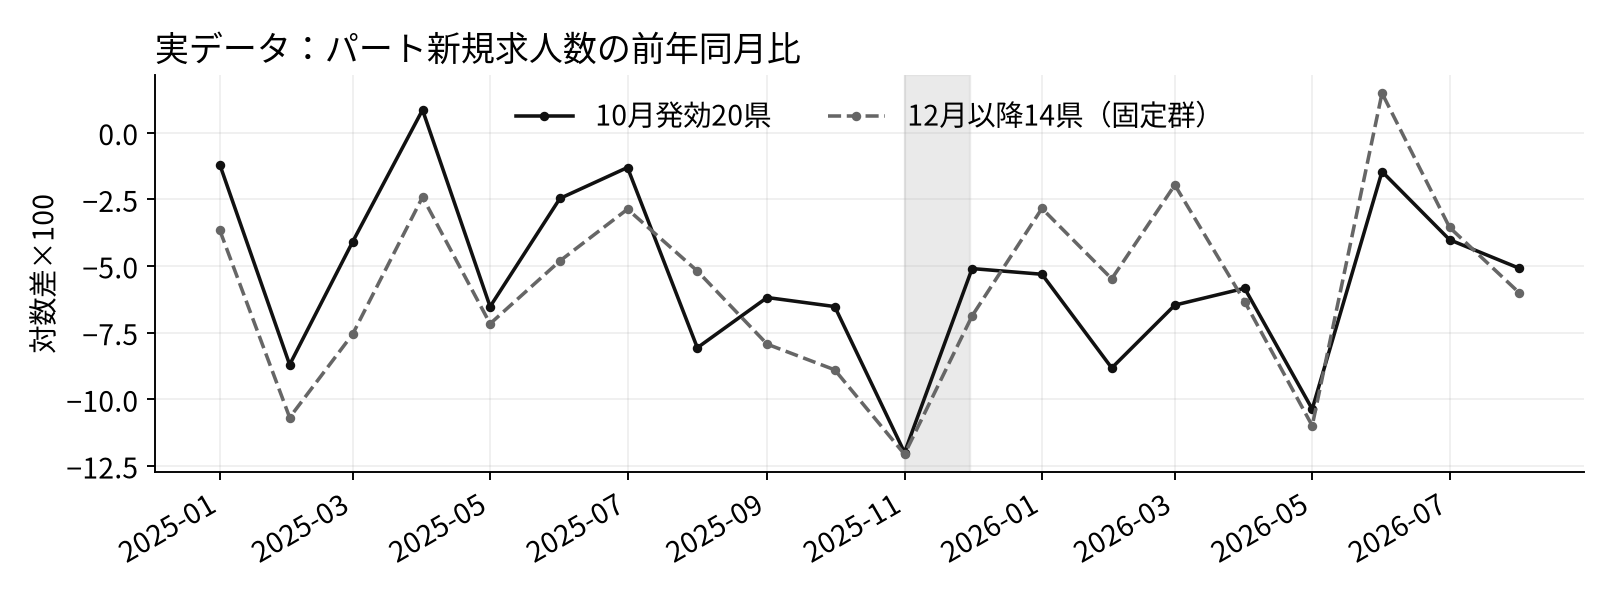

In [4]:
main=pd.read_csv(H/"results/main_contrasts.csv")
display(main[["pre_end","estimate","ci_low","ci_high","p_negative","p_two_sided"]])
display(pd.read_csv(H/"results/prefecture_d_pre9.csv").head())
display(Image(filename=str(H/"figures/actual_yoy.png")))

主差は−1.56、95%区間[−7.93, 4.82]。方向は既発表H1と同じだが、明確な負の差とは判断できない。1〜7月基準も併記し、都合のよい基準へ置き換えない。引上げ率を入れた補助OLSは比較可能性を保証しない。2024年の改定の影響も同比から差し引かれる。徳島は2024年11月1日発効で、2025年の晩群に含まれる。

In [5]:
display(pd.read_csv(H/"results/wage_increment_overlap.csv"))
print("引上げ率調整（補助）:",summary["controlled_ols_hc3"])
print("前年の同じ暦月差（無政策placeboではない）:",summary["prior_year_diagnostic"])

,group,min,max,mean
0,early,5.417025,7.628004,6.386977
1,late,6.477733,8.613445,7.782163


引上げ率調整（補助）: {'estimate': -1.3595874299989623, 'ci_low': -13.697078491129815, 'ci_high': 10.977903631131891, 'p': 0.8236458063304345, 'note': 'auxiliary association only; wage-increase control does not solve endogenous timing or overlap'}
前年の同じ暦月差（無政策placeboではない）: {'month': '2024-11', 'pre_end': 9, 'n_early': 20, 'n_late': 14, 'early_pre': np.float64(-6.1563380284183555), 'late_pre': np.float64(-10.03395451555698), 'early_post': np.float64(-4.884989285922413), 'late_post': np.float64(-6.933039674994949), 'early_d': np.float64(1.2713487424959435), 'late_d': np.float64(3.1009148405620306), 'estimate': np.float64(-1.829566098066087), 'se': np.float64(2.1476031554791803), 'df': np.float64(26.729515071701027), 'ci_low': np.float64(-6.238171189253521), 'ci_high': np.float64(2.579038993121347), 'p_two_sided': np.float64(0.40183220876194764), 'p_negative': np.float64(0.20091610438097382), 'baseline_year': 2024, 'note': '2024 same-cohort calendar diagnostic; 2024 policy is present, not no-policy

## 4. 主モデル：将来も採用を選ぶ企業
Hamermesh (1993), III.A、本文pp.4–5のgross/net調整費用と将来利潤に基づく授業用の二期簡略化（同論文そのものではない）。企業は今期と次期の募集枠$v_1,v_2\ge0$を選ぶ。$L_1=rL_0+qv_1$, $L_2=rL_1+qv_2$。

$$\max\ R(L_1)-w_1L_1-C(v_1)+\beta\{R(L_2)-\bar w_2L_2-C(v_2)\},\quad R(L)=aL-\frac b2L^2,\ C(v)=cv+\frac\kappa2v^2.$$

$\bar w_2$は既知の予想次期賃金。固定工時、同質労働、外生賃金、一定の残存率$r$・充足率$q$、裁員なし、期末価値ゼロを追加仮定する。資金制約・賃金設定力・マッチング市場均衡は含まない。DMPモデルとは呼ばない。法定時給をそのまま企業の一人当たり期間賃金に置換しない。詳しい解と条件はmethods.md。

内点では現在賃金の上昇は$v_1$を減らし$v_2$を増やす。後者は、今期の採用を減らした分を次期に相対的に補う効果で、次期の求人数が今期より多くなるという予測ではない。$r>0,\kappa>0$なら予想次期賃金の上昇は$v_1$も減らす。$\kappa=0$または$r=0$なら、このモデルの内点で先取り反応は消える。ゼロ募集の角点では内点導関数を適用しない。

すべて仮定値・推定ではない: {'a': 10.0, 'b': 1.0, 'q': 0.8, 'r': 0.8, 'beta': 0.95, 'kappa': 2.0, 'c': 0.2, 'L0': 3.0}


,scenario,w1,expected_w2,v1,v2,L1,L2,parameters
0,no_hike,4.0,4.0,1.566083,0.856881,3.652866,3.607798,assumed_not_estimated
1,late_anticipated,4.0,4.5,1.487609,0.720585,3.590088,3.448538,assumed_not_estimated
2,early_anticipated,4.5,4.5,1.351313,0.747018,3.481051,3.382455,assumed_not_estimated
3,larger_future_hike,4.0,5.0,1.409136,0.584289,3.527309,3.289278,assumed_not_estimated


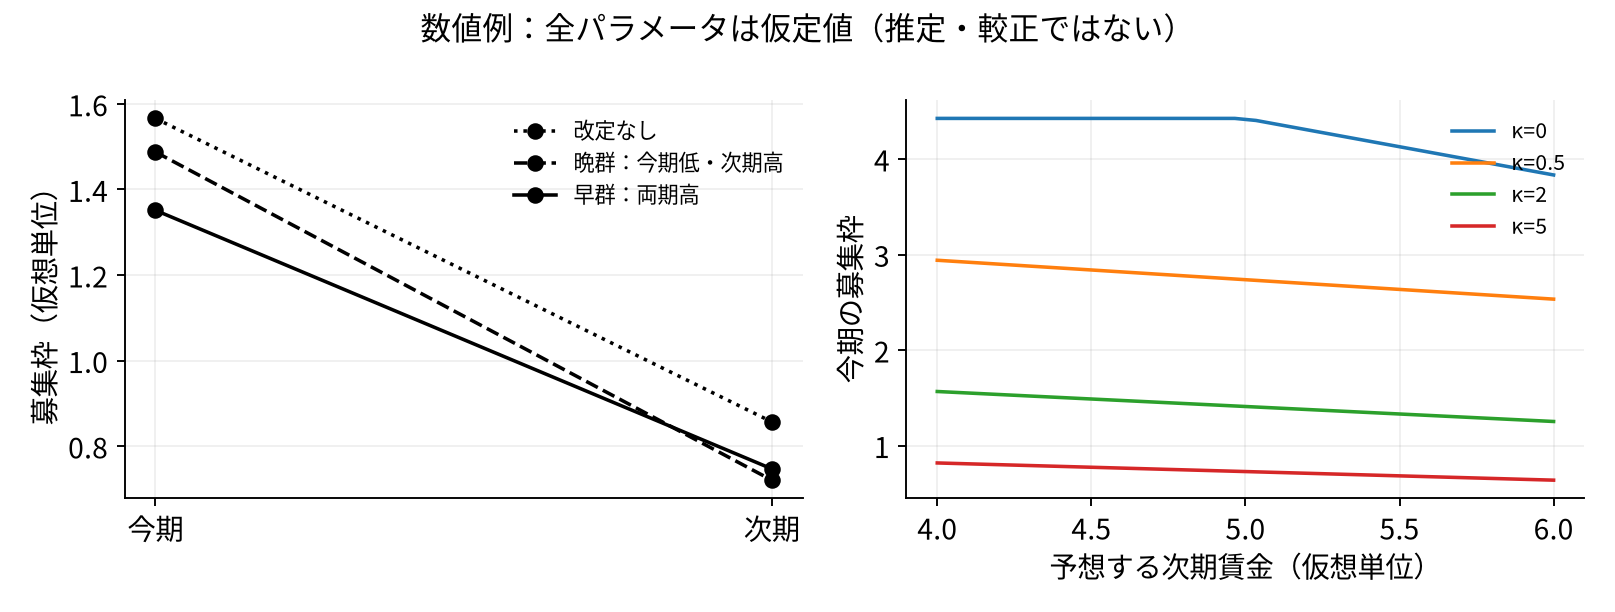

{'seed': 20261104, 'draws': 200, 'interior_draws': 134, 'all_kkt_pass': True, 'max_derivative_error': 1.202503652208975e-10, 'max_optimizer_objective_error': np.float64(9.521272659185342e-13), 'zero_kappa_and_zero_persistence_checked': True, 'zero_hiring_corner_checked': True}


In [6]:
print("すべて仮定値・推定ではない:",summary["assumed_parameters"])
display(pd.read_csv(H/"results/model_assumed_scenarios.csv"))
display(Image(filename=str(H/"figures/model_simulation.png")))
print(summary["model"])

## 5. その後の道筋は記述だけ
両群の需要・離職・充足率・賃上げ幅等が同じなら、今期の賃金だけ高い早群は今期募集が少なく、次期に晩群より多くなる、という条件付き制約がある。ただし実際は晩群の引上げ率が大きく、モデルの2期は特定の月と同一ではない。

4〜6月の早晩差から11月の早晩差を引くと−0.67、95%区間[−6.16, 4.82]。点推定に相対的な補いは見られないが不確実性が大きい。全県発効後の比較であり、catch-upや調整費用の存在を識別しない。

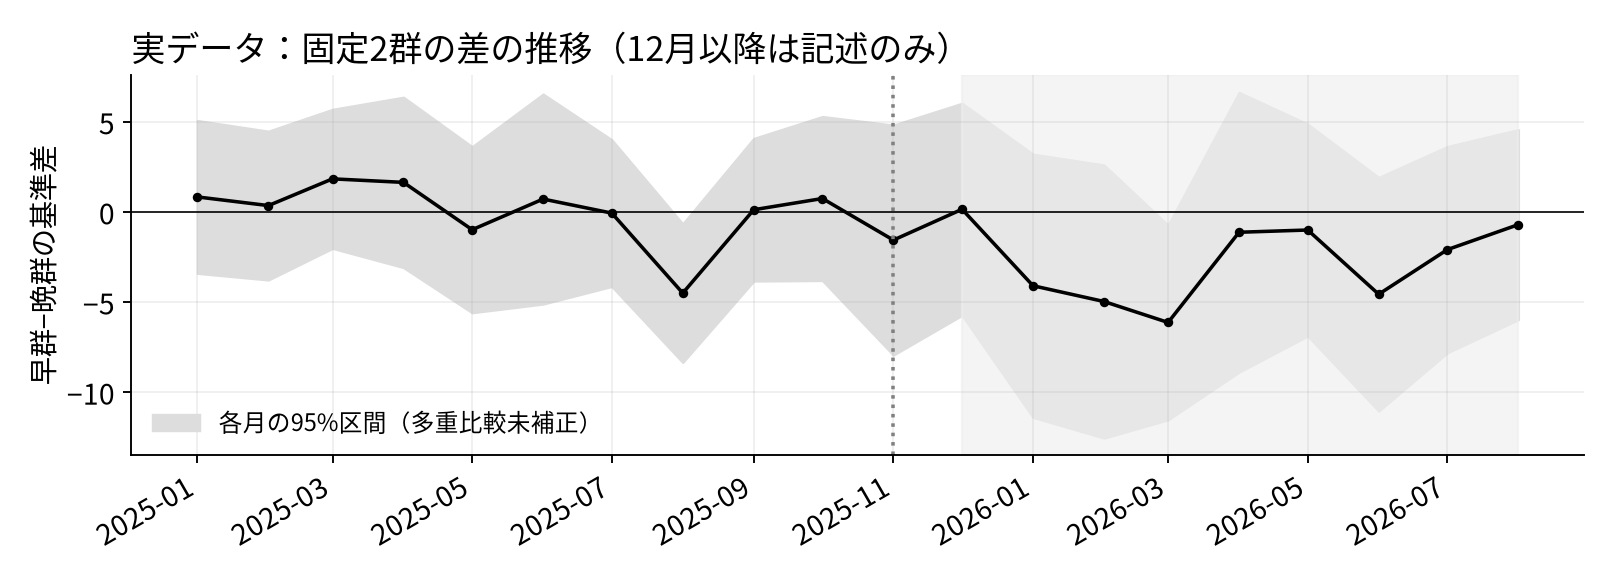

{'contrast': '(early-late Apr-Jun2026 mean y) minus (early-late Nov2025 y)', 'estimate': -0.6711878068361248, 'ci_low': -6.158002533918838, 'ci_high': 4.815626920246588, 'p_two_sided': 0.8047871971992092, 'not_causal': True}


In [7]:
display(Image(filename=str(H/"figures/actual_gap_path.png")))
print(summary["later_shape_diagnostic"])

## 結論と限界
今回の追加は、未来の賃金負担と採用を先送りする費用のトレードオフを明示したこと。統計手法を高度化したわけではない。先取り・動学的求人調整は既存研究にもあり、初の発見とは主張しない。実データが検査するのは時序・群間差の制約までで、$q,r,\kappa$や期待の形成は推定しない。県間の政策時期は内生的、受理地と就業地も一致するとは限らない。需要・他媒体への移行・労働供給・在籍者構成は競合説明となる。